# 02. CHIRPS로 본 2019년 가뭄: 얼마나 이례적이었나?

**프로젝트:** Cambodia-Climate-Water-Energy · **로드맵:** 3–4주차 (약 6시간, 세션 2–3회)

2019년 3–4월, 캄보디아는 가뭄으로 수력발전이 줄어 정전을 겪었어요. 이 노트북은 **관측 자료**로 그 가뭄을 확인해요.

| 장 | 질문 | 시간 |
| --- | --- | --- |
| 0–1 | CHIRPS 내려받기, 캄보디아 국경으로 자르기 | 40분 |
| 2 | 자료가 그럴듯한가? (연강수, 계절 사이클, 모델과 비교) | 30분 |
| 3 | 2019년은 몇 번째로 건조했나? (SPI 순위) | 60분 |
| 4 | 언제, 어디가 부족했나? (월별 이상치, 지도) | 50분 |
| 5 | 엘니뇨와 관련 있나? (ONI 합성 분석, 5주차 미리보기) | 50분 |
| 6 | 정리 | 20분 |

**CHIRPS란?** 위성 적외선 관측과 지상 관측소 자료를 합친 강수 자료예요. 1981년부터, 0.05°(약 5.5 km) 해상도로 **육지에만** 있어요. 관측소가 적은 열대 지역에서 널리 써요. 여기서는 영역을 잘라 받을 수 있는 컬럼비아대 IRI Data Library를 써요.

## 0. 환경 설정

In [1]:
!pip install -q regionmask cartopy

In [2]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import xarray as xr
import requests
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import mannwhitneyu

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False

BASE = ("1985", "2014")          # 01 노트북(CMIP6)과 같은 기준기간
LON, LAT = (102.0, 108.0), (10.0, 15.0)
print("xarray", xr.__version__, "| cartopy", HAS_CARTOPY)

xarray 2025.12.0 | cartopy True


### 01 노트북에서 가져온 함수
`spi_1d`는 2주차에 NaN 버그를 고친 버전이에요. 5주차에 이런 공용 함수를 `src/utils.py`로 옮겨서, 노트북마다 복사하지 않고 불러오게 바꿀 거예요.

In [3]:
def spi_1d(monthly_mm, months, window=3, cal_mask=None):
    # monthly_mm: 월 강수량(mm/month) 1차원 배열, months: 각 값의 달(1–12), cal_mask: 분포를 맞출 기준기간
    acc = pd.Series(monthly_mm).rolling(window, min_periods=window).sum().to_numpy()
    out = np.full_like(acc, np.nan, dtype=float)
    for m in range(1, 13):
        sel = months == m
        ref = acc[sel & cal_mask]
        ref = ref[~np.isnan(ref)]
        q = np.mean(ref <= 0)
        a, loc, scale = stats.gamma.fit(ref[ref > 0], floc=0)
        x = acc[sel]
        H = q + (1 - q) * stats.gamma.cdf(np.where(x > 0, x, 0), a, loc=0, scale=scale)
        H = np.where(x <= 0, q, H)
        out[sel] = stats.norm.ppf(np.clip(H, 1e-6, 1 - 1e-6))
    out[np.isnan(acc)] = np.nan          # 2주차 버그 수정
    return out

def area_mean(da):
    w = np.cos(np.deg2rad(da.lat))
    return da.weighted(w).mean(("lat", "lon"))   # 바다(NaN)는 자동으로 제외

## 1. CHIRPS 내려받기 (캄보디아 영역만)
IRI Data Library는 **주소(URL)에 영역을 적으면 그 부분만 잘라서** 보내 줘요. 전 지구 파일은 수십 GB지만, 캄보디아 영역은 수십 MB예요.

- `X/(102)(108)RANGEEDGES`: 경도 102–108°E
- `Y/(15)(10)RANGEEDGES`: 위도 10–15°N
- 끝의 `data.nc`: netCDF 파일로 받기

v2.0이 안 되면 자동으로 v3.0을 시도해요. 둘 다 실패하면 아래 "직접 받기" 안내를 따르세요.

In [4]:
%%time
FN = "chirps_cambodia_monthly.nc"
SOURCES = {
    "CHIRPS v2.0": "https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/.monthly/.global/.precipitation",
    "CHIRPS v3.0": "https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v3p0/.monthly/.global/.precipitation",
}

def iri_url(base):
    (x0, x1), (y0, y1) = LON, LAT
    return f"{base}/X/%28{x0}%29%28{x1}%29RANGEEDGES/Y/%28{y1}%29%28{y0}%29RANGEEDGES/data.nc"

SOURCE = None
for name, base in SOURCES.items():
    try:
        r = requests.get(iri_url(base), timeout=600)
        r.raise_for_status()
        open(FN, "wb").write(r.content)
        xr.open_dataset(FN, decode_times=False).close()       # 제대로 된 netCDF인지 확인
        SOURCE = name
        print(f"{name}: {len(r.content) / 1e6:.1f} MB 받음")
        break
    except Exception as e:
        print(f"{name} 실패: {type(e).__name__}: {str(e)[:150]}")

assert SOURCE, "자동 다운로드 실패. 아래 '직접 받기' 안내를 따르세요."

CHIRPS v2.0: 26.6 MB 받음
CPU times: user 936 ms, sys: 166 ms, total: 1.1 s
Wall time: 4min 49s


> **직접 받기 (자동 다운로드가 실패했을 때만):** 브라우저에서 IRI Data Library의 CHIRPS v2p0 monthly global precipitation 페이지 → *Data Selection*에서 경도 102–108, 위도 10–15 입력 → *Data Files*에서 netCDF 선택 → 받은 파일을 Colab 왼쪽 파일 창에 끌어다 놓고 이름을 `chirps_cambodia_monthly.nc`로 바꾸세요. 그다음 위 셀은 건너뛰고 아래 셀부터 실행하세요.

### 시간 좌표 풀기와 단위 확인
IRI 파일의 시간은 "1960년 1월부터 몇 번째 달"이라는 숫자(`months since 1960-01-01`)로 저장돼 있어요. xarray가 이 형식을 자동으로 풀지 못하는 경우가 많아서 직접 날짜로 바꿔요. **남이 만든 자료를 열 때는 늘 시간·단위·좌표부터 확인하는 습관**을 들이세요.

In [5]:
ds = xr.open_dataset(FN, decode_times=False)
var = list(ds.data_vars)[0]
da = ds[var]
da = da.rename({k: v for k, v in {"X": "lon", "Y": "lat", "T": "time",
                                  "longitude": "lon", "latitude": "lat"}.items() if k in da.dims})

tunits = ds[[d for d in ds.dims if d in ("T", "time")][0]].attrs.get("units", "")
m = re.match(r"months since (\d{4})-(\d{1,2})", tunits)
if m:
    t0 = pd.Timestamp(int(m.group(1)), int(m.group(2)), 1)
    dates = [t0 + pd.DateOffset(months=int(np.floor(v))) for v in da.time.values]
    da = da.assign_coords(time=pd.to_datetime(dates))
else:
    da = xr.decode_cf(ds)[var]
    da = da.rename({k: v for k, v in {"X": "lon", "Y": "lat", "T": "time"}.items() if k in da.dims})
    da["time"] = da.indexes["time"].to_datetimeindex() if hasattr(da.indexes["time"], "to_datetimeindex") else da.time
da = da.sortby("lat")

print("변수:", var, "| 단위:", da.attrs.get("units", "(없음)"), "| 시간 단위:", tunits)
print("기간:", str(da.time.values[0])[:7], "→", str(da.time.values[-1])[:7], "| 격자:", da.lat.size, "x", da.lon.size)

변수: precipitation | 단위: mm/month | 시간 단위: months since 1960-01-01
기간: 1981-01 → 2026-09 | 격자: 100 x 121


In [6]:
# 월 강수량(mm/month)으로 맞추기: 단위가 mm/day라면 그 달 일수를 곱해요
units = da.attrs.get("units", "").lower()
if "day" in units:
    pr_mm = da * da.time.dt.days_in_month
    print("mm/day → mm/month 변환함")
else:
    pr_mm = da
    print("단위를 mm/month로 간주 (아래 2장의 연강수로 꼭 확인하세요)")

# 마지막 해가 12월까지 안 찼으면 그 해는 연 단위 계산에서 빠지도록 기억해 두기
LAST_FULL_YEAR = int(pr_mm.time.dt.year[-1]) - (0 if int(pr_mm.time.dt.month[-1]) == 12 else 1)
print("마지막 완전한 해:", LAST_FULL_YEAR)

단위를 mm/month로 간주 (아래 2장의 연강수로 꼭 확인하세요)
마지막 완전한 해: 2025


### 캄보디아 국경으로 자르기
사각형 영역에는 태국·라오스·베트남 일부가 들어가요. CHIRPS는 해상도가 높아서 국경 마스크가 의미가 있어요. Natural Earth 국경 자료를 써요 (`regionmask`가 처음 실행할 때 내려받아요).

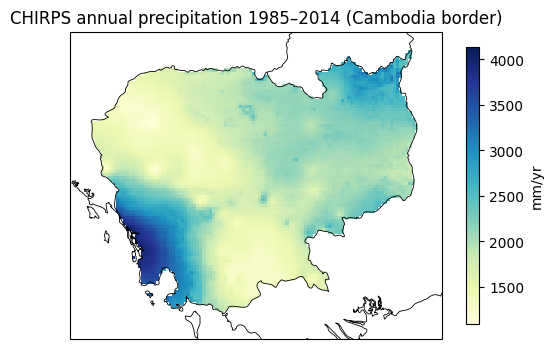

In [7]:
try:
    import regionmask
    countries = regionmask.defined_regions.natural_earth_v5_0_0.countries_50
    mask = countries.mask(pr_mm)
    pr_khm = pr_mm.where(mask == countries.map_keys("Cambodia"))
    MASK = "Cambodia border"
except Exception as e:
    print("국경 마스크 실패, 사각형 영역을 그대로 써요:", type(e).__name__, str(e)[:120])
    pr_khm = pr_mm
    MASK = "box (land only)"

fig = plt.figure(figsize=(6, 4.5))
ax = plt.axes(projection=ccrs.PlateCarree()) if HAS_CARTOPY else plt.axes()
clim_ann = pr_khm.sel(time=slice(*BASE)).groupby("time.year").sum(min_count=12).mean("year")
kw = dict(cmap="YlGnBu", cbar_kwargs={"label": "mm/yr", "shrink": 0.8})
if HAS_CARTOPY:
    clim_ann.plot(ax=ax, transform=ccrs.PlateCarree(), **kw)
    ax.coastlines(lw=0.6); ax.add_feature(cfeature.BORDERS, lw=0.6)
else:
    clim_ann.plot(ax=ax, **kw)
ax.set_title(f"CHIRPS annual precipitation {BASE[0]}–{BASE[1]} ({MASK})")
plt.show()

## 2. 자료가 그럴듯한가?
분석 전에 **알려진 사실과 맞는지** 확인해요. 캄보디아 연강수는 대략 1,400–2,000 mm이고, 남서부 카르다몸 산맥 쪽이 가장 많아요. 위 지도와 아래 숫자가 이와 맞는지 보세요.

기준기간 연강수: 1990 mm/yr
건기 1–4월 합계: 180 mm | 우기 5–10월 합계: 1719 mm
  MIROC6        : 1629 mm/yr (-18% vs CHIRPS)
  MPI-ESM1-2-LR : 1663 mm/yr (-16% vs CHIRPS)


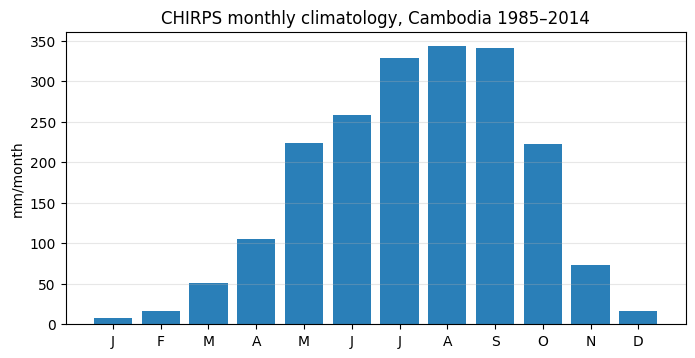

In [8]:
pr = area_mean(pr_khm).to_series()          # 캄보디아 평균 월 강수량 (pandas Series)
base = pr.loc[BASE[0]:BASE[1]]

clim = base.groupby(base.index.month).mean()
annual_base = base.groupby(base.index.year).sum().mean()
print(f"기준기간 연강수: {annual_base:.0f} mm/yr")
print(f"건기 1–4월 합계: {clim.loc[1:4].sum():.0f} mm | 우기 5–10월 합계: {clim.loc[5:10].sum():.0f} mm")

# 01 노트북의 모델 연강수와 비교 (2주차 7.3 결과). 모델은 바다를 포함한 사각형이라 완전히 같은 비교는 아니에요.
for model, val in {"MIROC6": 1629, "MPI-ESM1-2-LR": 1663}.items():
    print(f"  {model:14s}: {val} mm/yr ({(val / annual_base - 1) * 100:+.0f}% vs CHIRPS)")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(1, 13), clim.values, color="#2a7fb8")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("mm/month"); ax.set_title(f"CHIRPS monthly climatology, Cambodia {BASE[0]}–{BASE[1]}")
ax.grid(alpha=0.3, axis="y"); plt.show()

**확인할 것:** 01 노트북의 MIROC6 계절 사이클에서 6월에 강수가 살짝 꺼졌었죠. CHIRPS에서도 6월이 7월보다 적은가요? 그렇다면 몬순 초반의 소강기(mid-summer dry spell)가 실제 현상이고, 아니라면 모델의 편의예요.

## 3. 2019년은 몇 번째로 건조했나?
2주차에 만든 수력 관점의 세 지표를 관측으로 계산하고, 1982년 이후 모든 해 중 **순위**를 매겨요. 순위 1 = 가장 건조한 해예요.

| 지표 | 2019년 정전과의 관계 |
| --- | --- |
| 2018년 10월 SPI-6 | 2018년 우기에 저수지를 덜 채웠나? |
| 2019년 4월 SPI-3 | 2019년 건기(2–4월) 자체가 건조했나? |
| 2019년 4월 SPI-12 | 2018년 5월–2019년 4월, 1년 누적으로 부족했나? |
| 2019년 10월 SPI-6 | (덤) 정전 이후의 2019년 우기는? |

In [9]:
months = pr.index.month.values
years = pr.index.year.values
is_base = (years >= int(BASE[0])) & (years <= int(BASE[1]))

spi = {w: spi_1d(pr.values, months, window=w, cal_mask=is_base) for w in (3, 6, 12)}

def yearly(w, month):
    s = pd.Series(spi[w][months == month], index=years[months == month]).dropna()
    return s

def rank_of(s, year):
    # 1 = 가장 건조
    return int(s.rank(method="min").loc[year]), len(s)

checks = [
    ("2018 우기 (SPI-6, 10월)", 6, 10, 2018),
    ("2019 건기 (SPI-3, 4월)", 3, 4, 2019),
    ("1년 누적 (SPI-12, 2019년 4월)", 12, 4, 2019),
    ("2019 우기 (SPI-6, 10월)", 6, 10, 2019),
]
rows = []
for label, w, mon, yr in checks:
    s = yearly(w, mon)
    if yr in s.index:
        rk, n = rank_of(s, yr)
        rows.append({"지표": label, "SPI": round(float(s.loc[yr]), 2), "건조한 순위": f"{rk} / {n}",
                     "같은 수준 이하가 올 확률": f"{rk / n * 100:.0f}%"})
pd.DataFrame(rows).set_index("지표")

,SPI,건조한 순위,같은 수준 이하가 올 확률
지표,,,
"2018 우기 (SPI-6, 10월)",-0.54,13 / 45,29%
"2019 건기 (SPI-3, 4월)",-0.48,17 / 46,37%
"1년 누적 (SPI-12, 2019년 4월)",-0.64,14 / 45,31%
"2019 우기 (SPI-6, 10월)",-2.10,2 / 45,4%


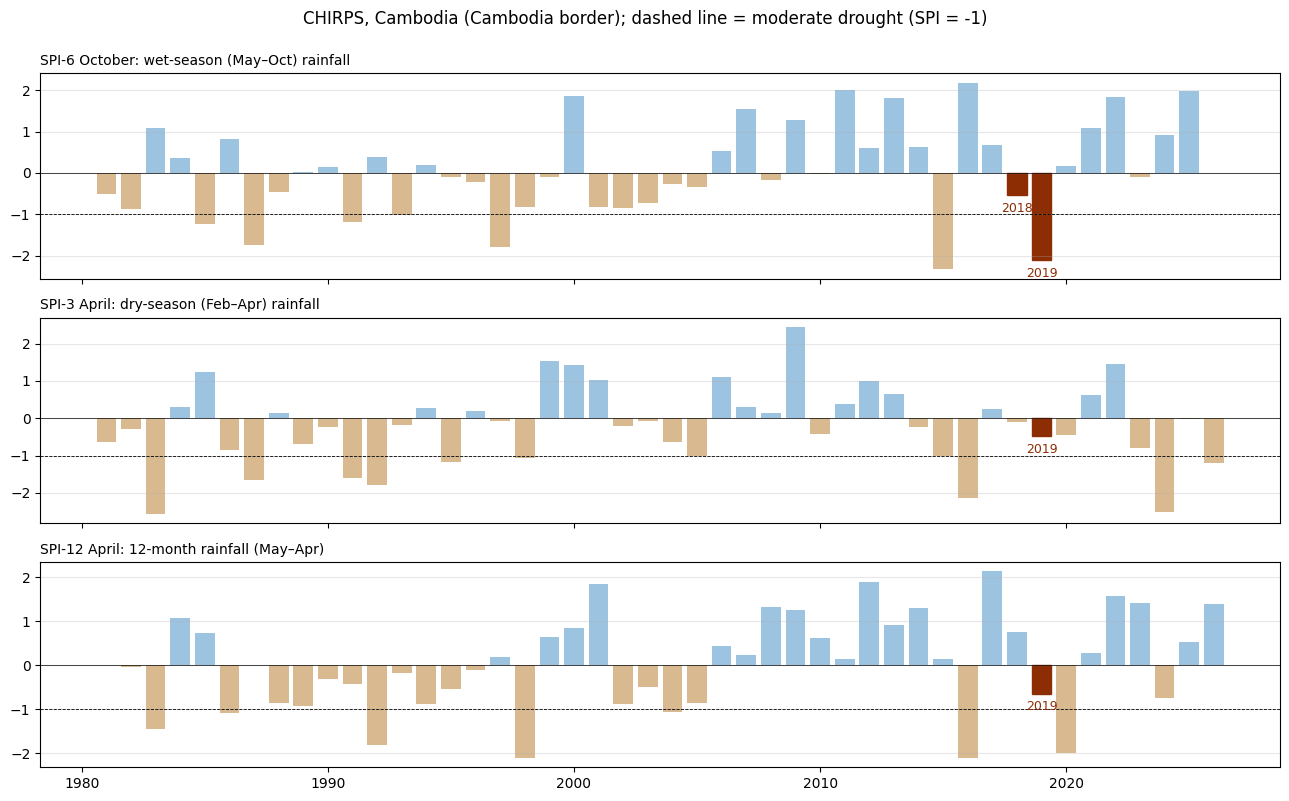

In [10]:
def bar_with_highlight(ax, s, highlight, title):
    colors = np.where(s.values < 0, "#d9b98f", "#9cc3e0")
    bars = ax.bar(s.index, s.values, color=colors, width=0.8)
    for yr in highlight:
        if yr in s.index:
            i = list(s.index).index(yr)
            bars[i].set_color("#8c2d04")
            ax.annotate(str(yr), (yr, s.loc[yr]), xytext=(0, -12 if s.loc[yr] < 0 else 4),
                        textcoords="offset points", ha="center", fontsize=9, color="#8c2d04")
    ax.axhline(-1, color="k", lw=0.6, ls="--")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(title, loc="left", fontsize=10); ax.grid(alpha=0.3, axis="y")

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
bar_with_highlight(axes[0], yearly(6, 10), [2018, 2019], "SPI-6 October: wet-season (May–Oct) rainfall")
bar_with_highlight(axes[1], yearly(3, 4), [2019], "SPI-3 April: dry-season (Feb–Apr) rainfall")
bar_with_highlight(axes[2], yearly(12, 4), [2019], "SPI-12 April: 12-month rainfall (May–Apr)")
fig.suptitle(f"CHIRPS, Cambodia ({MASK}); dashed line = moderate drought (SPI = -1)", y=0.995)
plt.tight_layout(); plt.show()

**해석 질문**
1. 2019년 정전은 **2018년 우기 부족**, **2019년 건기 부족**, **둘 다** 중 어느 쪽과 더 맞나요? 표의 순위로 근거를 대 보세요.
2. 2019년 SPI가 생각보다 덜 극단적이라면, 정전을 설명하는 다른 요인은 무엇일까요? (힌트: 2019년 4월 보도의 전력 수요 증가, 수입 전력 부족, 메콩 상류의 강수와 댐 운영)
3. 2019년 건기 SPI-3을 믿어도 될까요? 7.0에서 본 "건기 SPI의 한계"를 떠올리고, 아래 4장의 mm 이상치와 함께 판단해 보세요.

## 4. 언제, 어디가 부족했나?
SPI는 한 숫자로 요약해요. 이번에는 **달별로 풀어서** 봐요. 건기에는 평년 강수 자체가 적어서 %가 과장되기 쉬우니 **mm 차이**로 표시해요.

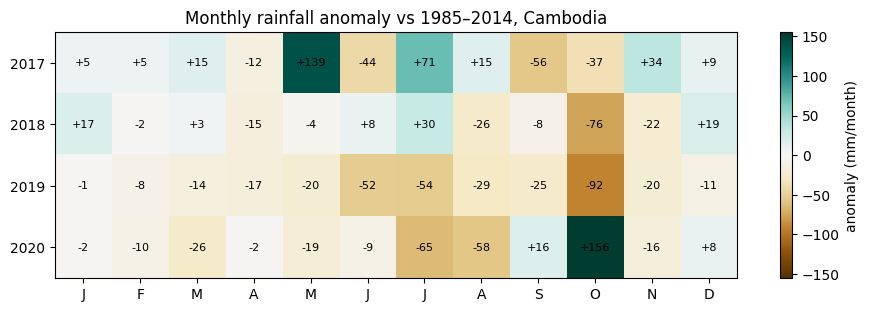

In [11]:
YEARS_SHOW = [2017, 2018, 2019, 2020]
anom = pd.DataFrame(index=YEARS_SHOW, columns=range(1, 13), dtype=float)
for y in YEARS_SHOW:
    for mth in range(1, 13):
        key = pd.Timestamp(y, mth, 1)
        if key in pr.index:
            anom.loc[y, mth] = pr.loc[key] - clim.loc[mth]

lim = np.nanmax(np.abs(anom.values))
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(anom.values.astype(float), cmap="BrBG", vmin=-lim, vmax=lim, aspect="auto")
for i in range(len(YEARS_SHOW)):
    for j in range(12):
        v = anom.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(12)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_yticks(range(len(YEARS_SHOW))); ax.set_yticklabels(YEARS_SHOW)
plt.colorbar(im, ax=ax, label="anomaly (mm/month)")
ax.set_title(f"Monthly rainfall anomaly vs {BASE[0]}–{BASE[1]}, Cambodia")
plt.show()

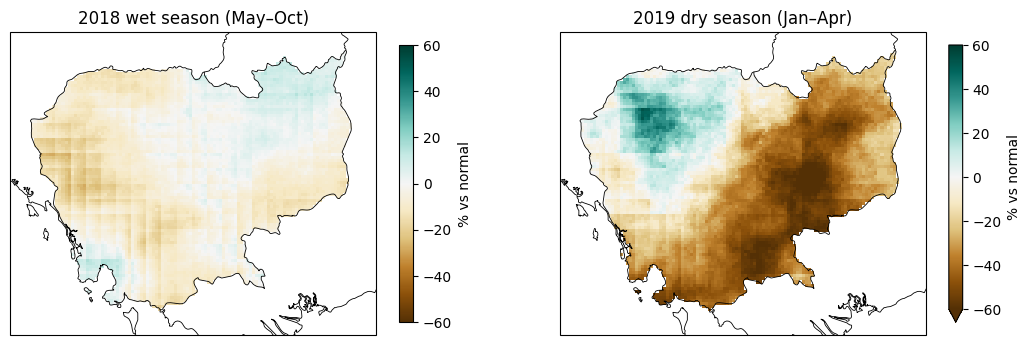

In [12]:
# 지도: 2018년 우기(5–10월)와 2019년 건기(1–4월)의 공간 패턴 (% 이상치)
def season_total(da, year, months_):
    sel = da.sel(time=[pd.Timestamp(year, m_, 1) for m_ in months_ if pd.Timestamp(year, m_, 1) in da.time.to_index()])
    return sel.sum("time", min_count=len(months_))

def season_clim(da, months_):
    b = da.sel(time=slice(*BASE))
    b = b.where(b.time.dt.month.isin(months_), drop=True)
    return b.groupby("time.year").sum(min_count=len(months_)).mean("year")

panels = [("2018 wet season (May–Oct)", 2018, [5, 6, 7, 8, 9, 10]),
          ("2019 dry season (Jan–Apr)", 2019, [1, 2, 3, 4])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5),
                         subplot_kw={"projection": ccrs.PlateCarree()} if HAS_CARTOPY else {})
for ax, (title, yr, ms) in zip(axes, panels):
    pct = (season_total(pr_khm, yr, ms) / season_clim(pr_khm, ms) - 1) * 100
    kw = dict(ax=ax, cmap="BrBG", vmin=-60, vmax=60, cbar_kwargs={"label": "% vs normal", "shrink": 0.8})
    if HAS_CARTOPY:
        pct.plot(transform=ccrs.PlateCarree(), **kw)
        ax.coastlines(lw=0.6); ax.add_feature(cfeature.BORDERS, lw=0.6)
    else:
        pct.plot(**kw)
    ax.set_title(title)
plt.show()

**해석 질문**
1. 2019년 우기의 시작(5–6월)은 평년과 비교해 어땠나요? 몬순 시작이 늦으면 건기가 사실상 길어져요.
2. 지도에서 부족이 컸던 곳은 캄보디아 수력댐이 몰려 있는 지역(북동부 스레퐁·세산 유역, 남서부 카르다몸 산맥)과 겹치나요? 7주차 수력 유역 분석에서 이 질문을 정확히 다뤄요.

## 5. 엘니뇨와 관련 있나? (5주차 미리보기)
**ONI(Oceanic Niño Index)**는 열대 태평양 해수면 온도 이상치예요. +0.5°C 이상이면 엘니뇨, −0.5°C 이하면 라니냐예요. 동남아시아는 엘니뇨 해에 건기가 더 건조해지는 경향이 알려져 있어요. 캄보디아 관측에서도 그런지, 2019년이 어디쯤인지 봐요.

여기서는 **DJF(12–2월) ONI**와 그 직후 **1–4월 강수**를 짝지어요. 예: DJF 2019 = 2018년 12월–2019년 2월.

> 참고: 미국 기후예측센터(CPC)는 최근 공식 감시 지표를 ONI에서 지구 온난화 추세를 뺀 **상대 ONI(RONI)**로 바꿨어요. 이 분석의 결론에는 큰 차이가 없지만, 논문에 쓸 때는 어떤 지표를 썼는지 밝혀 두세요.

In [13]:
def load_oni():
    # CPC 텍스트 파일 (SEAS YR TOTAL ANOM). 실패하면 NOAA PSL 형식을 시도해요.
    try:
        oni = pd.read_csv("https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt", sep=r"\s+")
        return oni[oni.SEAS == "DJF"].set_index("YR")["ANOM"].astype(float), "CPC oni.ascii.txt"
    except Exception as e:
        print("CPC 실패:", type(e).__name__)
    txt = requests.get("https://psl.noaa.gov/data/correlation/oni.data", timeout=60).text
    rows = {}
    for line in txt.splitlines():
        p = line.split()
        if len(p) == 13 and p[0].isdigit():
            vals = [float(v) for v in p[1:]]
            if vals[0] > -90:
                rows[int(p[0])] = vals[0]          # 첫 열 = DJF
    return pd.Series(rows, name="ANOM"), "NOAA PSL oni.data"

oni_djf, ONI_SRC = load_oni()
print("ONI 출처:", ONI_SRC, "| DJF 2019 =", oni_djf.get(2019))

ONI 출처: CPC oni.ascii.txt | DJF 2019 = 0.99


In [14]:
yrs = range(1982, LAST_FULL_YEAR + 1)
jfma = pd.Series({y: pr.loc[f"{y}-01":f"{y}-04"].sum() for y in yrs})
jfma_anom = (jfma / jfma.loc[int(BASE[0]):int(BASE[1])].mean() - 1) * 100
spi12_apr = yearly(12, 4)

df = pd.DataFrame({"ONI_DJF": oni_djf, "JFMA_anom_%": jfma_anom, "SPI12_Apr": spi12_apr}).dropna()
df["phase"] = pd.cut(df.ONI_DJF, [-9, -0.5, 0.5, 9], labels=["La Niña", "Neutral", "El Niño"])

print(df.groupby("phase", observed=True)[["JFMA_anom_%", "SPI12_Apr"]].agg(["mean", "count"]).round(2))
r_jfma = df[["ONI_DJF", "JFMA_anom_%"]].corr().iloc[0, 1]
r_spi = df[["ONI_DJF", "SPI12_Apr"]].corr().iloc[0, 1]
print(f"\n상관계수: ONI vs 1–4월 강수 r = {r_jfma:.2f} | ONI vs SPI-12(4월) r = {r_spi:.2f}  (n = {len(df)})")

nino, nina = df[df.phase == "El Niño"], df[df.phase == "La Niña"]
p = mannwhitneyu(nino["SPI12_Apr"], nina["SPI12_Apr"]).pvalue
print(f"엘니뇨 vs 라니냐 해의 SPI-12(4월) 차이: p = {p:.3f}")

        JFMA_anom_%       SPI12_Apr      
               mean count      mean count
phase                                    
La Niña   29.090000    16      0.83    16
Neutral  -13.170000    13      0.02    13
El Niño  -35.970001    15     -0.84    15

상관계수: ONI vs 1–4월 강수 r = -0.71 | ONI vs SPI-12(4월) r = -0.64  (n = 44)
엘니뇨 vs 라니냐 해의 SPI-12(4월) 차이: p = 0.000


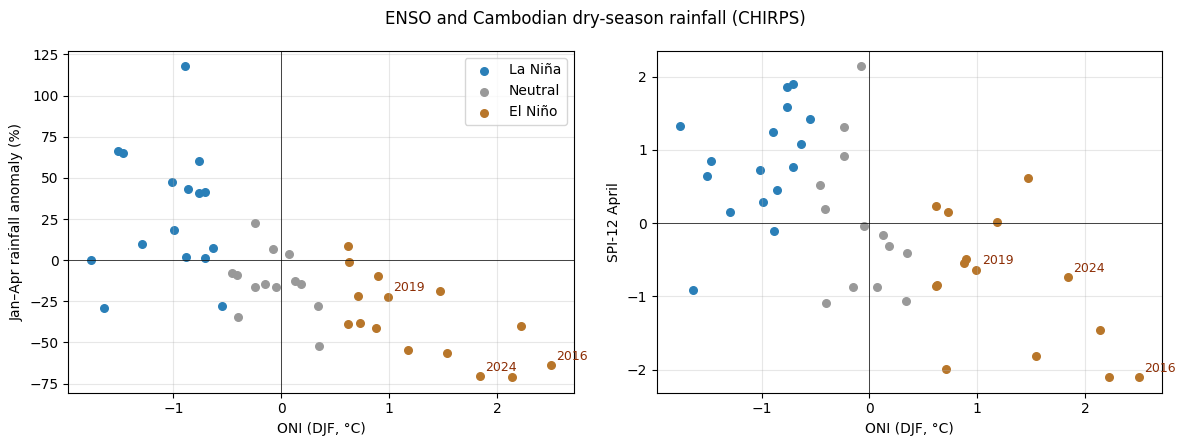

In [15]:
colors = {"La Niña": "#2a7fb8", "Neutral": "#999999", "El Niño": "#b8762a"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, ylab in zip(axes, ["JFMA_anom_%", "SPI12_Apr"], ["Jan–Apr rainfall anomaly (%)", "SPI-12 April"]):
    for ph, g in df.groupby("phase", observed=True):
        ax.scatter(g.ONI_DJF, g[col], color=colors[ph], label=ph, s=30)
    for yr in [2016, 2019, 2024]:
        if yr in df.index:
            ax.annotate(str(yr), (df.loc[yr, "ONI_DJF"], df.loc[yr, col]), xytext=(4, 4),
                        textcoords="offset points", fontsize=9, color="#8c2d04")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("ONI (DJF, °C)"); ax.set_ylabel(ylab); ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle("ENSO and Cambodian dry-season rainfall (CHIRPS)")
plt.tight_layout(); plt.show()

**해석 질문**
1. 엘니뇨 해들은 1–4월이 더 건조한가요? 상관계수의 부호와 크기는?
2. 2019년(DJF ONI가 약한 엘니뇨 수준)은 산점도에서 엘니뇨 해들 사이에 자연스럽게 놓이나요, 아니면 벗어나나요?
3. 강한 엘니뇨였던 2016년 건기와 비교하면? 2016년에도 캄보디아 가뭄이 컸다면, "엘니뇨 예보 → 건기 가뭄 경고"라는 4단계 EWS 아이디어의 근거가 돼요.
4. 1–4월은 원래 비가 적어서, ENSO가 건기 강수에 주는 영향이 수력에 미치는 영향은 제한적일 수 있어요. ONI와 SPI-12(4월)의 관계가 더 강하다면 무엇을 뜻할까요?

## 6. 정리
**메모**
1. 2019년 정전 직전 강수는 평년보다 약간 적은 수준이었다 (SPI-12 4월 -0.64, 45년 중 14위).
대신 2018년 10월(-76mm)에 우기 막바지 부족이 컸고, 2019년 건기는 동부·남부에서 40-60% 부족했다.
2. 2019년 몬순은 약하게 시작했고(6-7월 각 -50mm 이상), 2019년 우기는 1981년 이후 두번째로 건조했다
(SPI-6 10dnjf -2.10). 그 결과 2020년 4월 SPI-12(약 -2.0)가 2019년보다 훨씬 나빴다.
3. ENSO와 건기 강수의 관계는 강하다 (r = -0.71). 엘니뇨 해의 1-4월 강수는 평균 36% 적다.
4. 다음 질문: 강수 부족이 평범했는데 정전이 일어난 이유는? 2020년 건기에도 정전이 있었나?
댐 유역 단위로 보면 2019년은 더 극단적이었나?